In [ ]:

# Stage 5 - Load feature-engineered data

from google.colab import drive
import pandas as pd

drive.mount("/content/drive")

folder = "/content/drive/MyDrive/LendingClub_Project/stage4_data"

train_df = pd.read_parquet(
    folder + "/lending_club_train_stage4.parquet"
)

test_df = pd.read_parquet(
    folder + "/lending_club_test_stage4.parquet"
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("Same columns:", train_df.columns.equals(test_df.columns))
print("Missing values:", train_df.isna().sum().sum(),
      test_df.isna().sum().sum())


Mounted at /content/drive
Training shape: (1076280, 27)
Testing shape: (269070, 27)
Same columns: True
Missing values: 0 0


In [ ]:

# Stage 5 - Identify numerical and categorical features

X_train = train_df.drop(columns=["target"])
y_train = train_df["target"]

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))

print("\nCategorical columns:")
print(categorical_cols)

print("\nTarget distribution:")
print(y_train.value_counts())


Numerical features: 20
Categorical features: 6

Categorical columns:
['sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'addr_state']

Target distribution:
target
0    861401
1    214879
Name: count, dtype: int64


In [ ]:

# Stage 5 - Check categorical feature sizes

for col in categorical_cols:
    print(f"{col}: {X_train[col].nunique()} unique categories")

print("\nTotal training records:", len(X_train))


sub_grade: 35 unique categories
emp_length: 12 unique categories
home_ownership: 6 unique categories
verification_status: 3 unique categories
purpose: 14 unique categories
addr_state: 51 unique categories

Total training records: 1076280


In [ ]:

# Stage 5 - Build Logistic Regression pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor_lr = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(
        max_iter=300,
        class_weight="balanced",
        solver="saga",
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully!")


Logistic Regression pipeline created successfully!


In [ ]:

# Restore Stage 5 data and feature lists

from google.colab import drive
import pandas as pd

drive.mount("/content/drive")

folder = "/content/drive/MyDrive/LendingClub_Project/stage4_data"

train_df = pd.read_parquet(
    folder + "/lending_club_train_stage4.parquet"
)

test_df = pd.read_parquet(
    folder + "/lending_club_test_stage4.parquet"
)

X_train = train_df.drop(columns=["target"])
y_train = train_df["target"]

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Training data:", X_train.shape)
print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))


Mounted at /content/drive
Training data: (1076280, 26)
Numerical features: 20
Categorical features: 6


In [ ]:

# Stage 5 - Train Logistic Regression (Initial Experiment)

from sklearn.model_selection import train_test_split
import time

# Select a stratified sample from training data only
X_sample, _, y_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=100000,
    stratify=y_train,
    random_state=42
)

print("Training sample shape:", X_sample.shape)
print("Target distribution:")
print(y_sample.value_counts())

# Train the model
start_time = time.time()

logistic_model.fit(X_sample, y_sample)

training_time = time.time() - start_time

print("\nLogistic Regression trained successfully!")
print("Training time (seconds):", round(training_time, 2))


Training sample shape: (100000, 26)
Target distribution:
target
0    80035
1    19965
Name: count, dtype: int64

Logistic Regression trained successfully!
Training time (seconds): 48.75


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.model_selection import train_test_split


X_test_sample, _, y_test_sample, _ = train_test_split(
    X_test,
    y_test,
    train_size=50000,
    stratify=y_test,
    random_state=42
)


y_pred = logistic_model.predict(X_test_sample)

print("Accuracy:", round(accuracy_score(y_test_sample, y_pred), 4))
print("Precision:", round(precision_score(y_test_sample, y_pred), 4))
print("Recall:", round(recall_score(y_test_sample, y_pred), 4))
print("F1-score:", round(f1_score(y_test_sample, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_sample, y_pred))


Accuracy: 0.6465
Precision: 0.3184
Recall: 0.6752
F1-score: 0.4327

Confusion Matrix:
[[25586 14431]
 [ 3242  6741]]


In [ ]:

# Stage 5 - Create training and validation sets

from sklearn.model_selection import train_test_split

X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    stratify=y_sample,
    random_state=42
)

print("Model training:", X_model_train.shape)
print("Validation:", X_val.shape)

print("\nTraining target distribution:")
print(y_model_train.value_counts())

print("\nValidation target distribution:")
print(y_val.value_counts())


Model training: (80000, 26)
Validation: (20000, 26)

Training target distribution:
target
0    64028
1    15972
Name: count, dtype: int64

Validation target distribution:
target
0    16007
1     3993
Name: count, dtype: int64


In [ ]:



import time

start_time = time.time()

logistic_model.fit(X_model_train, y_model_train)

training_time_lr = time.time() - start_time

print("Logistic Regression retrained successfully!")
print("Training time (seconds):", round(training_time_lr, 2))
print("Training records:", len(X_model_train))


Logistic Regression retrained successfully!
Training time (seconds): 32.94
Training records: 80000


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:

# Stage 5 - Fix Logistic Regression convergence

from sklearn.linear_model import LogisticRegression
import time

# Update the classifier inside the existing pipeline
logistic_model.set_params(
    classifier=LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="lbfgs",
        random_state=42
    )
)

start_time = time.time()

logistic_model.fit(X_model_train, y_model_train)

training_time_lr = time.time() - start_time

print("Logistic Regression retrained!")
print("Training time (seconds):", round(training_time_lr, 2))
print("Iterations used:", logistic_model.named_steps["classifier"].n_iter_)


Logistic Regression retrained!
Training time (seconds): 5.69
Iterations used: [115]


In [ ]:

# Stage 5 - Logistic Regression Validation Results

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predict on validation data
y_val_pred_lr = logistic_model.predict(X_val)
y_val_prob_lr = logistic_model.predict_proba(X_val)[:, 1]

print("Logistic Regression - Validation Results")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_lr), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_lr), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_lr), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred_lr), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob_lr), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_lr))


Logistic Regression - Validation Results
Accuracy: 0.6462
Precision: 0.3176
Recall: 0.6719
F1-score: 0.4313
ROC-AUC: 0.7126

Confusion Matrix:
[[10242  5765]
 [ 1310  2683]]


In [ ]:

# Stage 5 - Build Random Forest Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Random Forest does not require StandardScaler
preprocessor_rf = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully!")


Random Forest pipeline created successfully!


In [ ]:



import time

start_time = time.time()

random_forest_model.fit(X_model_train, y_model_train)

training_time_rf = time.time() - start_time

print("Random Forest trained successfully!")
print("Training time (seconds):", round(training_time_rf, 2))
print("Training records:", len(X_model_train))


Random Forest trained successfully!
Training time (seconds): 51.11
Training records: 80000


In [ ]:



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


y_val_pred_rf = random_forest_model.predict(X_val)
y_val_prob_rf = random_forest_model.predict_proba(X_val)[:, 1]

print("Random Forest - Validation Results")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_rf), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_rf), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_rf), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob_rf), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))


Random Forest - Validation Results
Accuracy: 0.6936
Precision: 0.342
Recall: 0.5785
F1-score: 0.4298
ROC-AUC: 0.7129

Confusion Matrix:
[[11562  4445]
 [ 1683  2310]]


In [ ]:

# Stage 5 - Compare validation results

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_val, y_val_pred_lr),
        accuracy_score(y_val, y_val_pred_rf)
    ],
    "Precision": [
        precision_score(y_val, y_val_pred_lr),
        precision_score(y_val, y_val_pred_rf)
    ],
    "Recall": [
        recall_score(y_val, y_val_pred_lr),
        recall_score(y_val, y_val_pred_rf)
    ],
    "F1-score": [
        f1_score(y_val, y_val_pred_lr),
        f1_score(y_val, y_val_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, y_val_prob_lr),
        roc_auc_score(y_val, y_val_prob_rf)
    ]
})

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.6462,0.3176,0.6719,0.4313,0.7126
1,Random Forest,0.6936,0.3420,0.5785,0.4298,0.7129


In [ ]:

# Stage 6 - Check models and data are ready

print("Training records:", X_model_train.shape)
print("Validation records:", X_val.shape)

print("Logistic Regression ready:", logistic_model is not None)
print("Random Forest ready:", random_forest_model is not None)

print("Training target distribution:")
print(y_model_train.value_counts())


Training records: (80000, 26)
Validation records: (20000, 26)
Logistic Regression ready: True
Random Forest ready: True
Training target distribution:
target
0    64028
1    15972
Name: count, dtype: int64


In [ ]:

# Stage 6 - Logistic Regression Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone
import time

# Define cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Try different regularization strengths
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1.0]
}

lr_search = RandomizedSearchCV(
    estimator=clone(logistic_model),
    param_distributions=lr_param_grid,
    n_iter=3,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=2,
    refit=True
)

start_time = time.time()

lr_search.fit(X_model_train, y_model_train)

print("Logistic Regression tuning completed!")
print("Best parameters:", lr_search.best_params_)
print("Best cross-validation F1:", round(lr_search.best_score_, 4))
print("Tuning time (seconds):", round(time.time() - start_time, 2))


Logistic Regression tuning completed!
Best parameters: {'classifier__C': 1.0}
Best cross-validation F1: 0.4294
Tuning time (seconds): 22.42


In [ ]:

# Stage 6 - Evaluate Tuned Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

tuned_lr = lr_search.best_estimator_

y_val_pred_lr_tuned = tuned_lr.predict(X_val)
y_val_prob_lr_tuned = tuned_lr.predict_proba(X_val)[:, 1]

print("Tuned Logistic Regression - Validation Results")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_lr_tuned), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_lr_tuned), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_lr_tuned), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred_lr_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob_lr_tuned), 4))


Tuned Logistic Regression - Validation Results
Accuracy: 0.6462
Precision: 0.3176
Recall: 0.6719
F1-score: 0.4313
ROC-AUC: 0.7126


In [ ]:

# Stage 6 - Random Forest Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone
import time

rf_param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [10, 15, 20],
    "classifier__min_samples_leaf": [5, 10]
}

rf_search = RandomizedSearchCV(
    estimator=clone(random_forest_model),
    param_distributions=rf_param_grid,
    n_iter=4,
    scoring="f1",
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    random_state=42,
    n_jobs=2,
    refit=True
)

start_time = time.time()

rf_search.fit(X_model_train, y_model_train)

print("Random Forest tuning completed!")
print("Best parameters:", rf_search.best_params_)
print("Best cross-validation F1:", round(rf_search.best_score_, 4))
print("Tuning time (seconds):", round(time.time() - start_time, 2))


Random Forest tuning completed!
Best parameters: {'classifier__n_estimators': 50, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 10}
Best cross-validation F1: 0.4262
Tuning time (seconds): 309.72


========== STAGE 6 MODEL COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression - Before Tuning,0.6462,0.3176,0.6719,0.4313,0.7126
1,Logistic Regression - After Tuning,0.6462,0.3176,0.6719,0.4313,0.7126
2,Random Forest - Before Tuning,0.6936,0.3420,0.5785,0.4298,0.7129
3,Random Forest - After Tuning,0.6590,0.3219,0.6401,0.4284,0.7088



 Logistic Regression - Before Tuning
[[10242  5765]
 [ 1310  2683]]


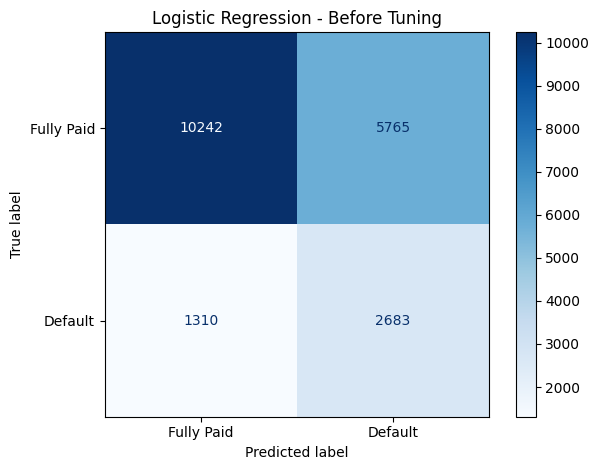


 Logistic Regression - After Tuning
[[10242  5765]
 [ 1310  2683]]


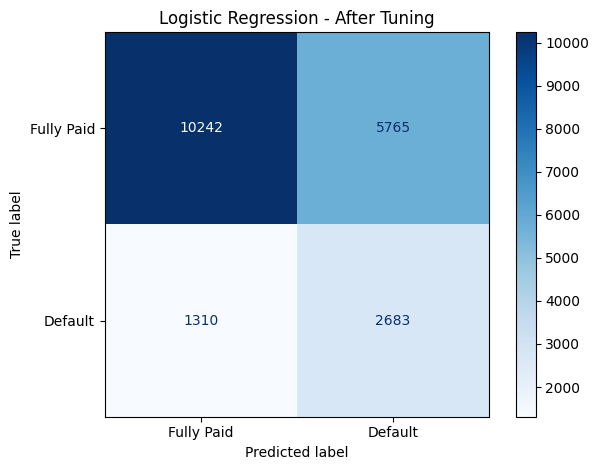


 Random Forest - Before Tuning
[[11562  4445]
 [ 1683  2310]]


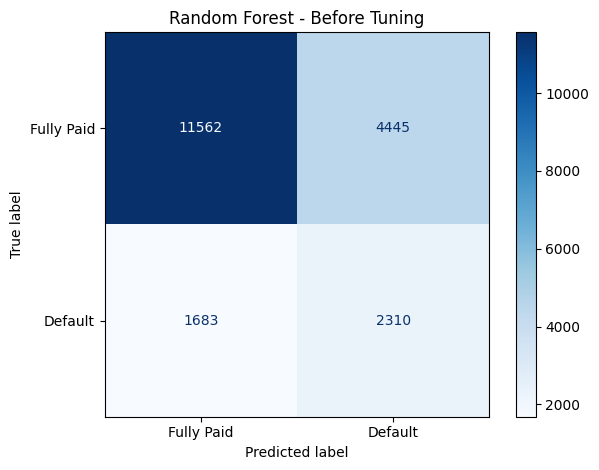


 Random Forest - After Tuning
[[10623  5384]
 [ 1437  2556]]


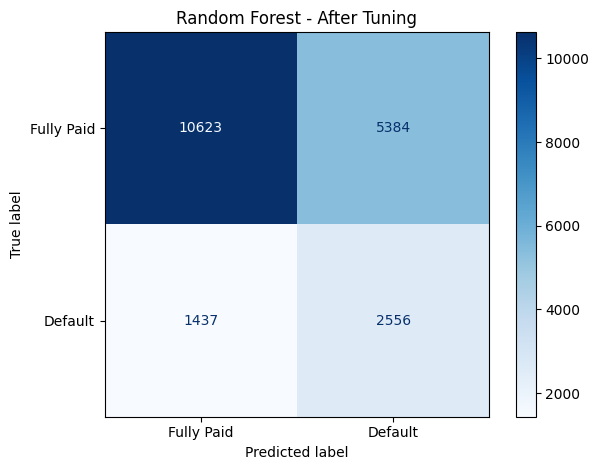

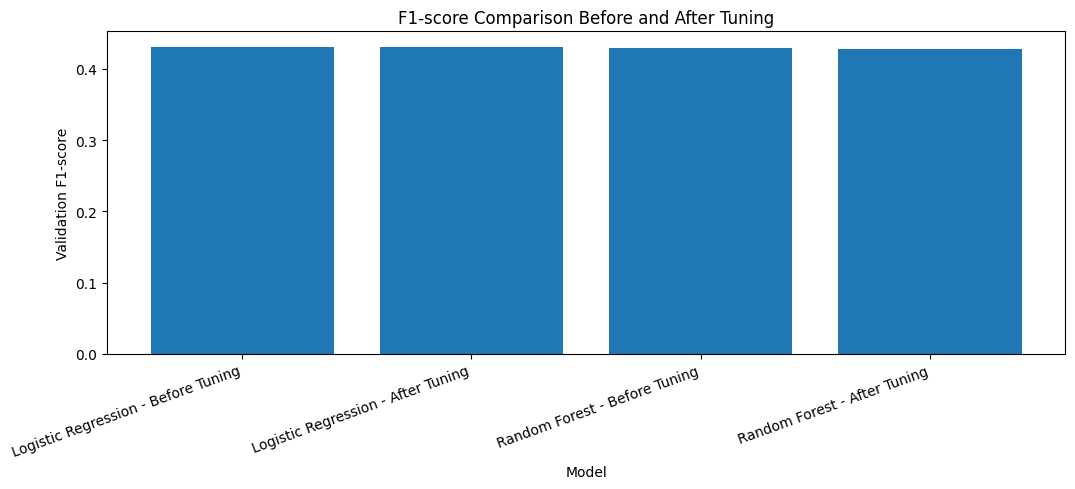


========== MODEL SELECTION ==========
Best model by validation F1-score: Logistic Regression - Before Tuning
Best validation F1-score: 0.4313

========== FILES SAVED ==========
Model saved: True
Comparison saved: True
Folder: /content/drive/MyDrive/LendingClub_Project/stage6_models

Stage 6 validation comparison completed!


In [ ]:

# =====================================================
# STAGE 6 - FINAL VALIDATION COMPARISON AND SAVE MODEL
# =====================================================

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Get the fitted models
models = {
    "Logistic Regression - Before Tuning": logistic_model,
    "Logistic Regression - After Tuning": lr_search.best_estimator_,
    "Random Forest - Before Tuning": random_forest_model,
    "Random Forest - After Tuning": rf_search.best_estimator_
}

# 2. Evaluate on the SAME validation data
results = []
predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

comparison_stage6 = pd.DataFrame(results)

print("========== STAGE 6 MODEL COMPARISON ==========")
display(comparison_stage6.round(4))

# 3. Display confusion matrices
for name, model in models.items():

    print("\n", name)

    cm = confusion_matrix(
        y_val,
        predictions[name],
        labels=[0, 1]
    )

    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Fully Paid", "Default"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(name)
    plt.tight_layout()
    plt.show()

# 4. Compare F1-scores visually
plt.figure(figsize=(11, 5))

plt.bar(
    comparison_stage6["Model"],
    comparison_stage6["F1-score"]
)

plt.title("F1-score Comparison Before and After Tuning")
plt.xlabel("Model")
plt.ylabel("Validation F1-score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# 5. Select model based on validation F1-score
best_index = comparison_stage6["F1-score"].idxmax()
best_name = comparison_stage6.loc[best_index, "Model"]
best_model = models[best_name]

print("\n========== MODEL SELECTION ==========")
print("Best model by validation F1-score:", best_name)
print(
    "Best validation F1-score:",
    round(comparison_stage6.loc[best_index, "F1-score"], 4)
)

# 6. Save model and results to Google Drive
save_folder = (
    "/content/drive/MyDrive/LendingClub_Project/stage6_models"
)

os.makedirs(save_folder, exist_ok=True)

model_path = os.path.join(
    save_folder,
    "selected_loan_default_model.joblib"
)

results_path = os.path.join(
    save_folder,
    "stage6_model_comparison.csv"
)

joblib.dump(best_model, model_path)
comparison_stage6.to_csv(results_path, index=False)

print("\n========== FILES SAVED ==========")
print("Model saved:", os.path.exists(model_path))
print("Comparison saved:", os.path.exists(results_path))
print("Folder:", save_folder)

print("\nStage 6 validation comparison completed!")


In [ ]:

# Stage 7 - Verify saved model

import os
import joblib

model_path = (
    "/content/drive/MyDrive/LendingClub_Project/"
    "stage6_models/selected_loan_default_model.joblib"
)

print("Model file exists:", os.path.exists(model_path))

saved_model = joblib.load(model_path)

print("Model type:", type(saved_model).__name__)
print("Pipeline steps:", list(saved_model.named_steps.keys()))

print("Expected features:",
      len(saved_model.feature_names_in_))


Model file exists: True
Model type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']
Expected features: 26


In [ ]:

# Stage 7 - Check saved model size and prediction

import os

model_size_mb = os.path.getsize(model_path) / (1024 * 1024)

print("Model size (MB):", round(model_size_mb, 2))

# Check prediction using existing validation records
sample = X_val.head(3)

predictions = saved_model.predict(sample)
probabilities = saved_model.predict_proba(sample)[:, 1]

print("Sample predictions:", predictions)
print("Default probabilities:", probabilities.round(4))


Model size (MB): 0.01
Sample predictions: [0 1 0]
Default probabilities: [0.4439 0.8322 0.474 ]


In [ ]:

# Stage 7 - Prepare Streamlit feature configuration

import os
import json
import pandas as pd
import numpy as np

app_folder = "/content/drive/MyDrive/LendingClub_Project/stage7_app"
os.makedirs(app_folder, exist_ok=True)

# Use training data only for default values
feature_names = saved_model.feature_names_in_.tolist()

# Engineered features will be calculated automatically
auto_features = [
    "loan_to_income_ratio",
    "zero_income_flag"
]

input_features = [
    col for col in feature_names
    if col not in auto_features
]

numeric_defaults = {}
categorical_options = {}
categorical_defaults = {}

for col in input_features:
    if pd.api.types.is_numeric_dtype(X_model_train[col]):
        numeric_defaults[col] = float(
            X_model_train[col].median()
        )
    else:
        options = sorted(
            X_model_train[col].dropna().astype(str).unique().tolist()
        )
        categorical_options[col] = options
        categorical_defaults[col] = str(
            X_model_train[col].mode().iloc[0]
        )

config = {
    "feature_names": feature_names,
    "input_features": input_features,
    "numeric_defaults": numeric_defaults,
    "categorical_options": categorical_options,
    "categorical_defaults": categorical_defaults,
    "loan_to_income_median": 0.2,
    "loan_to_income_cap": 0.5
}

config_path = os.path.join(app_folder, "feature_config.json")

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Configuration saved:", os.path.exists(config_path))
print("Total model features:", len(feature_names))
print("User/default input features:", len(input_features))
print("Automatically calculated features:", auto_features)
print("Categorical columns:", len(categorical_options))
print("Numerical input columns:", len(numeric_defaults))


Configuration saved: True
Total model features: 26
User/default input features: 24
Automatically calculated features: ['loan_to_income_ratio', 'zero_income_flag']
Categorical columns: 6
Numerical input columns: 18


In [ ]:

# Stage 7 - Create Streamlit application

import os

app_folder = "/content/drive/MyDrive/LendingClub_Project/stage7_app"
os.makedirs(app_folder, exist_ok=True)

app_code = r'''
import json
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="Loan Default Risk Prediction",
    page_icon="🏦",
    layout="wide"
)

APP_DIR = Path(__file__).resolve().parent

@st.cache_resource
def load_model():
    return joblib.load(APP_DIR / "selected_loan_default_model.joblib")

@st.cache_data
def load_config():
    with open(APP_DIR / "feature_config.json", "r", encoding="utf-8") as f:
        return json.load(f)

st.title("🏦 Loan Default Risk Prediction")
st.write(
    "This application estimates loan default risk using "
    "a machine learning model trained on historical Lending Club data."
)

st.info(
    "Educational demonstration only. Predictions are estimates, "
    "not guarantees or automated lending decisions."
)

try:
    model = load_model()
    config = load_config()
except Exception as error:
    st.error(f"Unable to load application files: {error}")
    st.stop()

feature_names = config["feature_names"]
numeric_defaults = config["numeric_defaults"]
categorical_options = config["categorical_options"]
categorical_defaults = config["categorical_defaults"]

st.subheader("Enter Borrower and Loan Information")
st.caption(
    "Fields initially contain typical values from the training dataset. "
    "Review and change them before making a prediction."
)

important_fields = [
    "loan_amnt",
    "annual_inc",
    "int_rate",
    "term",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "sub_grade"
]

all_inputs = {}

def show_input(col):
    label = col.replace("_", " ").title()

    if col in categorical_options:
        options = categorical_options[col]
        default = categorical_defaults[col]
        default_index = options.index(default) if default in options else 0

        return st.selectbox(
            label,
            options=options,
            index=default_index,
            key=col
        )

    default_value = float(numeric_defaults[col])

    return st.number_input(
        label,
        min_value=0.0,
        value=max(0.0, default_value),
        key=col,
        format="%.4f"
    )

col1, col2 = st.columns(2)

for index, field in enumerate(important_fields):
    if field not in config["input_features"]:
        continue

    with (col1 if index % 2 == 0 else col2):
        all_inputs[field] = show_input(field)

with st.expander("Additional borrower and credit information"):
    for field in config["input_features"]:
        if field not in all_inputs:
            all_inputs[field] = show_input(field)

if st.button("Predict Loan Default Risk", type="primary"):

    annual_income = float(all_inputs["annual_inc"])
    loan_amount = float(all_inputs["loan_amnt"])

    zero_income_flag = int(annual_income == 0)

    if annual_income > 0:
        loan_to_income_ratio = loan_amount / annual_income
    else:
        loan_to_income_ratio = float(
            config["loan_to_income_median"]
        )

    loan_to_income_ratio = min(
        loan_to_income_ratio,
        float(config["loan_to_income_cap"])
    )

    all_inputs["zero_income_flag"] = zero_income_flag
    all_inputs["loan_to_income_ratio"] = loan_to_income_ratio

    if all_inputs["fico_range_low"] > all_inputs["fico_range_high"]:
        st.error("FICO range low cannot exceed FICO range high.")
        st.stop()

    input_df = pd.DataFrame([all_inputs])
    input_df = input_df[feature_names]

    prediction = int(model.predict(input_df)[0])
    probability = float(model.predict_proba(input_df)[0, 1])

    st.subheader("Prediction Result")

    st.metric(
        "Estimated Model Default Probability",
        f"{probability * 100:.2f}%"
    )

    if prediction == 1:
        st.warning("Prediction: Higher Default Risk (Class 1)")
    else:
        st.success("Prediction: Lower Default Risk (Class 0)")

    st.write(
        "The classification uses the model's default threshold of 0.50. "
        "The displayed probability is a model estimate and has not "
        "been established as a calibrated real-world risk."
    )

    st.caption(
        "The model uses loan terms available at origination. "
        "It was trained on historical data and should not be used "
        "as the sole basis for real lending decisions."
    )
'''

app_path = os.path.join(app_folder, "app.py")

with open(app_path, "w", encoding="utf-8") as f:
    f.write(app_code)

# Check Python syntax
import ast
ast.parse(app_code)

print("App saved:", os.path.exists(app_path))
print("App path:", app_path)
print("Python syntax: Valid")


App saved: True
App path: /content/drive/MyDrive/LendingClub_Project/stage7_app/app.py
Python syntax: Valid


In [ ]:

# Stage 7 - Prepare deployment files

import os
import shutil

app_folder = "/content/drive/MyDrive/LendingClub_Project/stage7_app"

source_model = (
    "/content/drive/MyDrive/LendingClub_Project/"
    "stage6_models/selected_loan_default_model.joblib"
)

destination_model = os.path.join(
    app_folder,
    "selected_loan_default_model.joblib"
)

# Copy the trained model into the app folder
shutil.copy2(source_model, destination_model)

# Create Streamlit requirements
requirements = """streamlit
pandas
scikit-learn
joblib
numpy
pyarrow
"""

with open(
    os.path.join(app_folder, "requirements.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(requirements)

print("Deployment files:")
for filename in sorted(os.listdir(app_folder)):
    print(
        filename,
        "-",
        round(
            os.path.getsize(
                os.path.join(app_folder, filename)
            ) / 1024,
            2
        ),
        "KB"
    )

print("\nReady files:", len(os.listdir(app_folder)))


Deployment files:
app.py - 4.19 KB
feature_config.json - 3.55 KB
requirements.txt - 0.05 KB
selected_loan_default_model.joblib - 7.55 KB

Ready files: 4


In [ ]:

# Stage 7 - Download Streamlit deployment files

import shutil
from google.colab import files

app_folder = "/content/drive/MyDrive/LendingClub_Project/stage7_app"

zip_path = shutil.make_archive(
    "/content/Loan_Default_Streamlit_App",
    "zip",
    app_folder
)

print("ZIP created:", zip_path)
files.download(zip_path)


ZIP created: /content/Loan_Default_Streamlit_App.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

import sklearn

print("scikit-learn version:", sklearn.__version__)


scikit-learn version: 1.6.1


In [1]:
import sklearn
print(sklearn.__version__)

1.6.1


In [1]:

# Stage 6.6 - Check final testing files

from google.colab import drive
import os

drive.mount("/content/drive")

test_path = (
    "/content/drive/MyDrive/LendingClub_Project/"
    "stage4_data/lending_club_test_stage4.parquet"
)

model_path = (
    "/content/drive/MyDrive/LendingClub_Project/"
    "stage6_models/selected_loan_default_model.joblib"
)

print("Test data exists:", os.path.exists(test_path))
print("Saved model exists:", os.path.exists(model_path))


ValueError: mount failed

In [2]:

from google.colab import drive
import os

drive.mount("/content/drive", force_remount=True)

test_path = "/content/drive/MyDrive/LendingClub_Project/stage4_data/lending_club_test_stage4.parquet"

model_path = "/content/drive/MyDrive/LendingClub_Project/stage6_models/selected_loan_default_model.joblib"

print("Test data exists:", os.path.exists(test_path))
print("Saved model exists:", os.path.exists(model_path))


Mounted at /content/drive
Test data exists: True
Saved model exists: True


In [3]:

# Stage 6.6 - Evaluate saved model on test data

import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Load the saved model and test data
final_model = joblib.load(model_path)
test_df = pd.read_parquet(test_path)

# Separate features and target
X_test = test_df.drop(columns=["target"])
y_test = test_df["target"]

# Predict loan outcomes
y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Final Model - Test Results")
print("Test records:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1-score:", round(f1_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


Final Model - Test Results
Test records: 269070
Accuracy: 0.6472
Precision: 0.3183
Recall: 0.6716
F1-score: 0.4319
ROC-AUC: 0.7151

Confusion Matrix:
[[138068  77282]
 [ 17642  36078]]
